# SECOM fault detection: logistic regression vs. random forest

**Task.** Each of the 1,567 wafers has 590 sensor readings and a pass/fail result from in-house line testing. The goal is to flag wafers likely to fail. SECOM has no fault-type labels, so this is **binary fault detection**: the positive class is *fail* (6.6% of wafers).

**Design, fixed before modeling:**

| Element | Choice |
|---|---|
| Baseline | Majority class: predict "pass" for every wafer |
| Models | L2 logistic regression and a random forest, both on all 442 sensors that survive cleaning (no feature selection) |
| Outliers and scale | Logistic regression: a quantile transform maps each sensor's readings to ranks on a normal scale, which bounds extreme readings and removes skew. Random forest: nothing, because tree splits depend only on the order of readings |
| Cost rule | A missed failure costs as much as 10 false alarms, so a wafer is flagged when its predicted risk is at least 1/11 ≈ 0.091. No class weights or resampling: the cost enters only at the threshold, so both models' risks must be honest probabilities |
| Validation | Stratified 5-fold CV repeated 5 times (25 outer folds, the same for every model). Logistic regression tunes C by inner 5-fold CV on log-loss; the forest tunes its leaf size and calibrates its risks on out-of-bag predictions. Plus a train-early, test-late check |
| Metrics | Primary: balanced accuracy. Decision metric: cost per wafer. Also fail-class recall and precision, ROC-AUC, PR-AUC, log-loss and calibration |

**Experiments:** E1 majority baseline · E2 logistic regression on standardized sensors · E3 logistic regression on quantile-transformed sensors · E4 calibrated random forest · E5 E3 and E4 trained on early wafers, tested on late ones.

**How to run.** In Colab, choose *Run all* and upload `secom.data` and `secom_labels.data` when prompted. Expect about 10 minutes on Colab's free tier, almost all of it in the cross-validation loop (Section 5).

*The EDA is the same as in the earlier logistic regression notebook, and the numbers quoted in its text come from that run. Text marked **✍ After running** is for your own reading of the results, which don't exist until the notebook has run on the real data.*

## 1. Setup

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter
import matplotlib.dates as mdates
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV
from sklearn.calibration import calibration_curve
from sklearn.metrics import (balanced_accuracy_score, roc_auc_score, average_precision_score, precision_score,
                             brier_score_loss, log_loss, confusion_matrix)

RANDOM_SEED = 42
COST_FN, COST_FP = 10, 1                    # a missed failure costs as much as 10 false alarms
THRESHOLD = COST_FP / (COST_FP + COST_FN)   # flag a wafer when its predicted risk is at least 1/11
MAX_MISSING = 0.40                          # drop sensors missing in more than 40% of wafers
EXTREME_SD = 3                              # EDA only: a reading this many SD from its sensor's mean counts as extreme
N_SPLITS, N_REPEATS = 5, 5                  # outer CV: 5 folds x 5 repeats = 25 held-out evaluations

C_GRID = np.logspace(-5, -1, 9)             # logistic regression: L2 strengths to try (smaller C = more shrinkage)
N_TREES = 200                               # random forest: trees per forest
LEAF_SIZES = [1, 3, 10, 30]                 # random forest: minimum wafers per leaf to try (larger = smoother risks)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

print(f"numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print(f"Cost threshold: 1/{COST_FP + COST_FN} = {THRESHOLD:.3f}")

numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1
Cost threshold: 1/11 = 0.091


In [ ]:
# One quiet chart style for every figure: hairline grid, thin marks, blue = pass, orange = fail
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "font.size": 10, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})

## 2. Load the data
### 2.1 Upload the SECOM files
Same upload code as the earlier notebook. Outside Colab it reads the two files from the working directory instead.

In [ ]:
try:
    from google.colab import files          # in Colab: the same upload widget as before
    print("Please upload 'secom.data' and 'secom_labels.data'.")
    uploaded = files.upload()
    filenames = list(uploaded.keys())
except ImportError:                          # outside Colab: read the files from the working directory
    filenames = ["secom.data", "secom_labels.data"]
    print("Not running in Colab: reading the files from the working directory.")

data_file, labels_file = None, None
for filename in filenames:
    if "labels" in filename.lower():
        labels_file = filename
    else:
        data_file = filename

print(f"Data file:   {data_file}")
print(f"Labels file: {labels_file}")

Please upload 'secom.data' and 'secom_labels.data'.


Saving secom.data to secom.data
Saving secom_labels.data to secom_labels.data
Data file:   secom.data
Labels file: secom_labels.data


### 2.2 Load and merge

In [ ]:
# secom.data: 1567 wafers x 590 sensor readings, whitespace-delimited, no header, NaN = missing
X_raw = pd.read_csv(data_file, sep=r"\s+", header=None)
X_raw.columns = [f"sensor_{i+1}" for i in range(X_raw.shape[1])]

# secom_labels.data: label (-1 = pass, 1 = fail) and a quoted timestamp
labels_raw = pd.read_csv(labels_file, sep=r"\s+", header=None, names=["label", "timestamp"])
assert len(X_raw) == len(labels_raw), "Row count mismatch between data and labels files!"

y = (labels_raw["label"] == 1).astype(int).to_numpy()      # 1 = fail = positive class
timestamp = pd.to_datetime(labels_raw["timestamp"], format="%d/%m/%Y %H:%M:%S")

print(f"X shape: {X_raw.shape} | failures: {y.sum()} of {len(y)} ({y.mean():.1%})")
print(f"Time span: {timestamp.min():%d %b %Y} to {timestamp.max():%d %b %Y} | rows already in time order: {timestamp.is_monotonic_increasing}")

X shape: (1567, 590) | failures: 104 of 1567 (6.6%)
Time span: 19 Jul 2008 to 17 Oct 2008 | rows already in time order: True


## 3. Exploratory data analysis
Each part ends with the decision it informs, for each model.

### 3.1 Class balance and time

Pass: 1463 (93.4%) | Fail: 104 (6.6%) | imbalance 14.1 : 1
Failure rate by month: Jul 22.2% (n=63), Aug 9.2% (n=555), Sep 2.9% (n=590), Oct 6.1% (n=359)


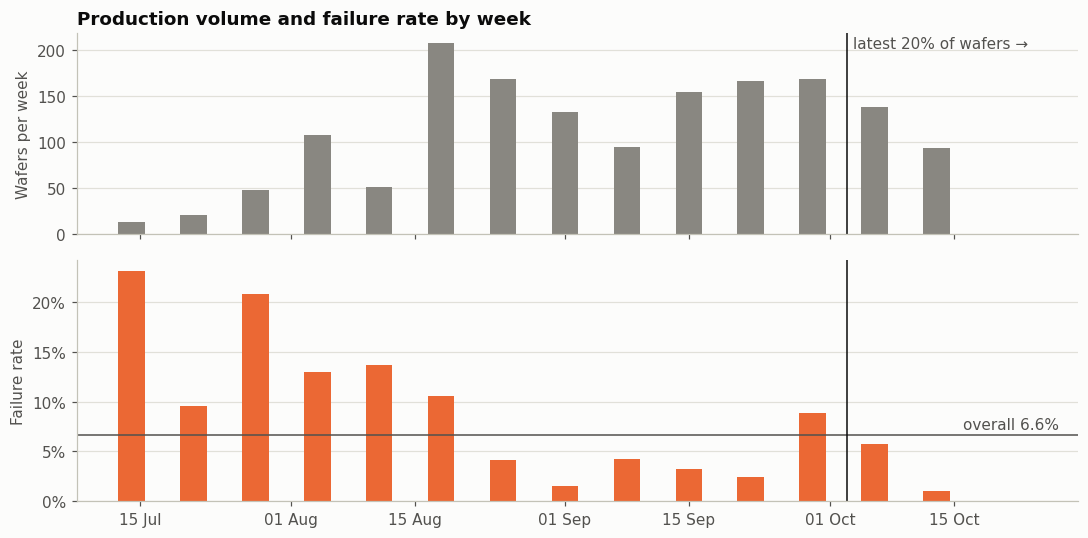

In [ ]:
n_fail = int(y.sum())
n_pass = len(y) - n_fail
print(f"Pass: {n_pass} ({n_pass / len(y):.1%}) | Fail: {n_fail} ({n_fail / len(y):.1%}) | imbalance {n_pass / n_fail:.1f} : 1")

fails = pd.Series(y)
monthly = fails.groupby(timestamp.dt.to_period("M")).agg(["size", "mean"])
print("Failure rate by month: " + ", ".join(f"{p.strftime('%b')} {r['mean']:.1%} (n={int(r['size'])})"
                                             for p, r in monthly.iterrows()))

weekly = fails.groupby(timestamp.dt.to_period("W").dt.start_time).agg(["size", "mean"])
n_early = int(round(0.8 * len(y)))          # rows are in time order: the latest 20% start here (Section 8)
time_cut = timestamp.iloc[n_early]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
ax1.bar(weekly.index, weekly["size"], width=3, color=MUTED)
ax1.set_ylabel("Wafers per week")
ax1.set_title("Production volume and failure rate by week")
ax2.bar(weekly.index, weekly["mean"], width=3, color=ORANGE)
ax2.axhline(y.mean(), color=INK_2, linewidth=1)
ax2.set_xlim(right=weekly.index[-1] + pd.Timedelta(days=16))
ax2.annotate(f"overall {y.mean():.1%}", (weekly.index[-1] + pd.Timedelta(days=3), y.mean()), xytext=(0, 4),
             textcoords="offset points", ha="left", color=INK_2)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax2.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax2.set_ylabel("Failure rate")
for ax in (ax1, ax2):
    ax.axvline(time_cut, color=INK, linewidth=1)
ax1.annotate("latest 20% of wafers →", (time_cut, ax1.get_ylim()[1]), xytext=(4, -2),
             textcoords="offset points", va="top", color=INK_2)
plt.tight_layout()
plt.show()

**Finding.** Failures are 6.6% of wafers, about 14 passes for every failure. The failure rate also shifts over time: 22% of July's wafers failed, 9% in August, 3% in September and 6% in October.

**Decision.** Accuracy is useless here, because always predicting "pass" already scores 93%. So is *weighted* precision, which is dominated by the pass class (Section 6 shows the baseline scores about 0.87 on it). The metrics are balanced accuracy and cost per wafer. Neither model gets class weights or resampling: the 10:1 cost is handled at the threshold, so the risks must stay honest probabilities. Random CV mixes the high- and low-failure periods, so a time-ordered check (E5) tests whether results hold on later wafers.

### 3.2 Missing values, constant sensors and duplicates

Sensors with any missing value: 538 of 590 (435 of them missing in under 1% of wafers)
Sensors missing in more than 40% of wafers: 32. No sensor is missing in between 17.4% and 45.6% of wafers, so any cutoff in that gap drops the same sensors.
Constant sensors: 116 | sensors kept after cleaning: 442 of 590
Duplicate wafers (identical rows): 0 | duplicate sensors among those kept (identical columns): 0
Wafers missing at least one kept reading: 589 (38%). Their failure rate is 6.3%, vs 6.9% for complete wafers.


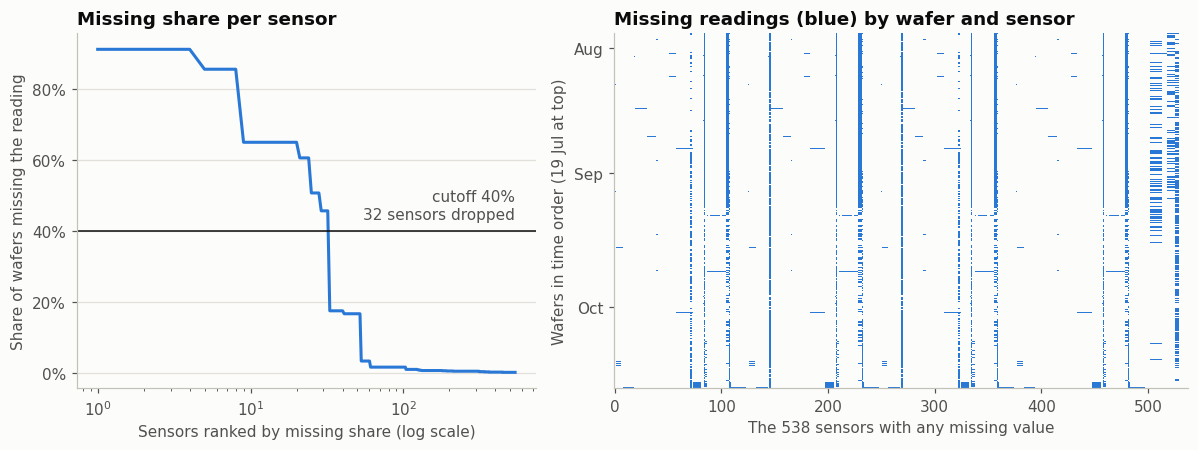

In [ ]:
missing_share = X_raw.isna().mean()
high_missing = missing_share > MAX_MISSING
constant = ~(X_raw.max() > X_raw.min())          # a single value across all wafers
kept = ~(high_missing | constant)

below, above = missing_share[~high_missing].max(), missing_share[high_missing].min()
print(f"Sensors with any missing value: {(missing_share > 0).sum()} of {X_raw.shape[1]} "
      f"({(missing_share.between(0, 0.01, inclusive='right')).sum()} of them missing in under 1% of wafers)")
print(f"Sensors missing in more than {MAX_MISSING:.0%} of wafers: {high_missing.sum()}. No sensor is missing in between "
      f"{below:.1%} and {above:.1%} of wafers, so any cutoff in that gap drops the same sensors.")
print(f"Constant sensors: {constant.sum()} | sensors kept after cleaning: {kept.sum()} of {X_raw.shape[1]}")
print(f"Duplicate wafers (identical rows): {X_raw.duplicated().sum()} | "
      f"duplicate sensors among those kept (identical columns): {X_raw.loc[:, kept].T.duplicated().sum()}")

has_gap = X_raw.loc[:, kept].isna().any(axis=1).to_numpy()
print(f"Wafers missing at least one kept reading: {has_gap.sum()} ({has_gap.mean():.0%}). "
      f"Their failure rate is {y[has_gap].mean():.1%}, vs {y[~has_gap].mean():.1%} for complete wafers.")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ranked = missing_share[missing_share > 0].sort_values(ascending=False).to_numpy()
axa.plot(np.arange(1, len(ranked) + 1), ranked, color=BLUE)
axa.axhline(MAX_MISSING, color=INK, linewidth=1)
axa.annotate(f"cutoff {MAX_MISSING:.0%}\n{high_missing.sum()} sensors dropped", (len(ranked), MAX_MISSING),
             xytext=(0, 6), textcoords="offset points", ha="right", va="bottom", color=INK_2)
axa.set_xscale("log")
axa.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axa.set_xlabel("Sensors ranked by missing share (log scale)")
axa.set_ylabel("Share of wafers missing the reading")
axa.set_title("Missing share per sensor")

cols = missing_share.index[missing_share > 0]
axb.imshow(X_raw[cols].isna().to_numpy(), aspect="auto", interpolation="nearest",
           cmap=ListedColormap([SURFACE, BLUE]))
month_rows = pd.Series(np.arange(len(y))).groupby(timestamp.dt.to_period("M")).first().iloc[1:]
axb.set_yticks(month_rows.to_numpy(), [p.strftime("%b") for p in month_rows.index])
axb.set_xlabel(f"The {len(cols)} sensors with any missing value")
axb.set_ylabel("Wafers in time order (19 Jul at top)")
axb.set_title("Missing readings (blue) by wafer and sensor")
axb.grid(False)
plt.tight_layout()
plt.show()

**Finding.** Most gaps are small: 435 sensors are missing in under 1% of wafers. 32 sensors are missing in more than 40% of wafers. No sensor falls between 17.4% and 45.6% missing, so the exact cutoff doesn't matter. 116 sensors are constant, and there are no duplicate wafers or duplicate sensors. In the map, gaps often hit a group of sensors on the same wafer (the horizontal streaks). Wafers with a gap fail at about the usual rate (6.3% vs 6.9%).

**Decision (both models).** Drop the constant and mostly-missing sensors once, before modeling, leaving 442. This step uses no labels, and because of the clear gap between 17% and 46% missing, every training fold would drop the same sensors anyway. Fill the remaining gaps with training-fold medians inside each model's pipeline.

### 3.3 Scales, skew and outliers

Sensor standard deviations span 7.8 orders of magnitude (1.0e-04 to 6,550).
Strongly skewed sensors (|skewness| > 2): 247 of 442.
Readings more than 3 SD from their sensor's mean: 0.88% of all readings, spread over 1268 of 1567 wafers.
Sensors with a reading beyond 6 SD: 299; the most extreme reading is 40 SD from its sensor's mean.


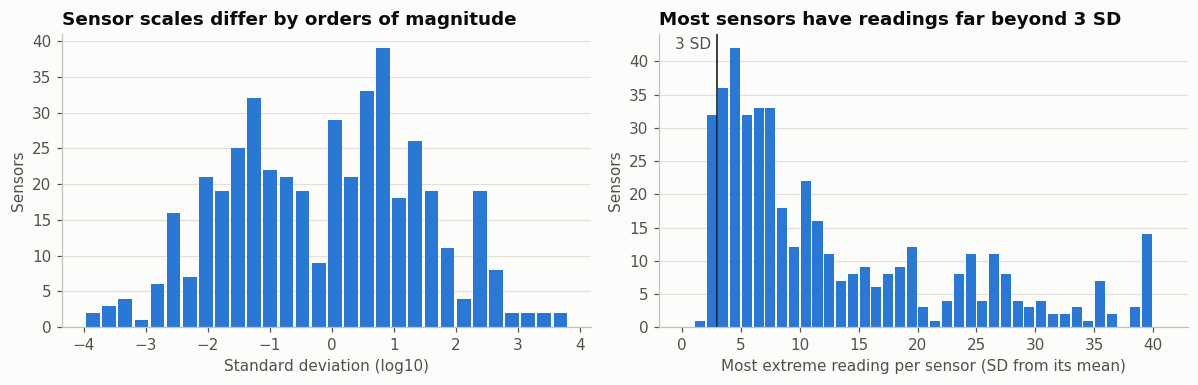

In [ ]:
X_kept = X_raw.loc[:, kept]
X_filled = X_kept.fillna(X_kept.median())        # description only: the model imputes inside each CV fold
sd = X_filled.std()
z = (X_filled - X_filled.mean()) / sd
max_abs_z = z.abs().max()

print(f"Sensor standard deviations span {np.log10(sd.max() / sd.min()):.1f} orders of magnitude "
      f"({sd.min():.1e} to {sd.max():,.0f}).")
print(f"Strongly skewed sensors (|skewness| > 2): {(X_filled.skew().abs() > 2).sum()} of {len(sd)}.")
print(f"Readings more than {EXTREME_SD} SD from their sensor's mean: {(z.abs() > EXTREME_SD).to_numpy().mean():.2%} of all readings, "
      f"spread over {(z.abs() > EXTREME_SD).any(axis=1).sum()} of {len(z)} wafers.")
print(f"Sensors with a reading beyond 6 SD: {(max_abs_z > 6).sum()}; "
      f"the most extreme reading is {max_abs_z.max():.0f} SD from its sensor's mean.")

fig, (axa, axb) = plt.subplots(1, 2, figsize=(11, 3.6))
axa.hist(np.log10(sd), bins=30, color=BLUE, rwidth=0.85)
axa.set_xlabel("Standard deviation (log10)")
axa.set_ylabel("Sensors")
axa.set_title("Sensor scales differ by orders of magnitude")
axb.hist(max_abs_z, bins=np.arange(0, np.ceil(max_abs_z.max()) + 2, 1), color=BLUE, rwidth=0.85)
axb.axvline(EXTREME_SD, color=INK, linewidth=1)
axb.annotate(f"{EXTREME_SD} SD", (EXTREME_SD, axb.get_ylim()[1]), xytext=(-4, -2), textcoords="offset points",
             ha="right", va="top", color=INK_2)
axb.set_xlabel("Most extreme reading per sensor (SD from its mean)")
axb.set_ylabel("Sensors")
axb.set_title("Most sensors have readings far beyond 3 SD")
plt.tight_layout()
plt.show()

**Finding.** Sensor scales span almost 8 orders of magnitude, and more than half the sensors are strongly skewed. Extreme readings are common: 1,268 of the 1,567 wafers have at least one reading beyond 3 SD, 299 sensors have a reading beyond 6 SD, and the most extreme reading is 40 SD from its mean.

**Decision.**
- **Logistic regression** adds up weighted readings, so a 40 SD reading can dominate a wafer's score and make the model overconfident. The earlier notebook fixed this by standardizing and clipping at ±3 SD, but the ±3 was picked after seeing results. Here a **quantile transform** replaces both steps: each reading becomes its rank among the training wafers, mapped onto a normal scale. Scale, skew and outliers are handled at once, with nothing to tune. E2 (standardized only) vs E3 (quantile) tests whether it matters.
- **Random forest:** nothing to do. A split such as "sensor_59 > 2.1" depends only on the order of the readings, so scaling or transforming changes nothing, and an extreme reading just lands on one side of a split.

### 3.4 Redundancy between sensors

Sensor pairs with |r| > 0.9: 345 (127 of them above 0.99)
Sensors with at least one near-twin (|r| > 0.9): 303 of 442
Principal components needed for 90% / 95% of the variance: 128 / 161 of 442


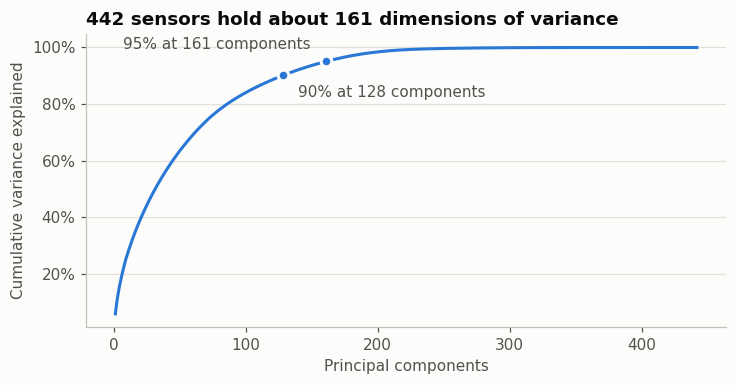

In [ ]:
corr = np.corrcoef(z.to_numpy(), rowvar=False)
pair_r = np.abs(corr[np.triu_indices_from(corr, k=1)])
has_twin = ((np.abs(corr) > 0.9).sum(axis=0) - 1) > 0
cum_var = np.cumsum(PCA().fit(z.to_numpy()).explained_variance_ratio_)
n90, n95 = np.searchsorted(cum_var, [0.90, 0.95]) + 1

print(f"Sensor pairs with |r| > 0.9: {(pair_r > 0.9).sum()} ({(pair_r > 0.99).sum()} of them above 0.99)")
print(f"Sensors with at least one near-twin (|r| > 0.9): {has_twin.sum()} of {len(has_twin)}")
print(f"Principal components needed for 90% / 95% of the variance: {n90} / {n95} of {len(cum_var)}")

fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.plot(np.arange(1, len(cum_var) + 1), cum_var, color=BLUE)
for k, frac, offset, align in ((n90, 0.90, (10, -14), "left"), (n95, 0.95, (-10, 8), "right")):
    ax.plot(k, cum_var[k - 1], "o", color=BLUE, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"{frac:.0%} at {k} components", (k, cum_var[k - 1]), xytext=offset,
                textcoords="offset points", ha=align, color=INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_xlabel("Principal components")
ax.set_ylabel("Cumulative variance explained")
ax.set_title(f"{len(cum_var)} sensors hold about {n95} dimensions of variance")
plt.tight_layout()
plt.show()

**Finding.** Many sensors are near-copies of each other: 303 of the 442 have a partner with |r| > 0.9, and 161 principal components carry 95% of the variance.

**Decision.**
- **Logistic regression:** L2 regularization, which shares weight across near-copies instead of picking one at random, and keeps 442 features from overfitting 104 failures. C is tuned by inner CV.
- **Random forest:** no change needed; each split samples a subset of sensors, so near-copies take turns.
- **Both:** read single-sensor importance with care, because a near-copy can stand in for any sensor.

### 3.5 How much signal single sensors carry

Single-sensor AUC, real labels:     median 0.524, best 0.692; 12 sensors above 0.60
Single-sensor AUC, shuffled labels: median 0.520, best 0.589; 0 sensors above 0.60


,AUC,Spearman correlation with time
sensor_60,0.692,-0.44
sensor_104,0.668,-0.52
sensor_511,0.636,-0.41
sensor_478,0.621,-0.22
sensor_206,0.619,-0.21
sensor_130,0.619,-0.31
sensor_29,0.616,0.59
sensor_34,0.611,-0.15


Time order alone separates fail from pass with AUC 0.636: early wafers fail more often.


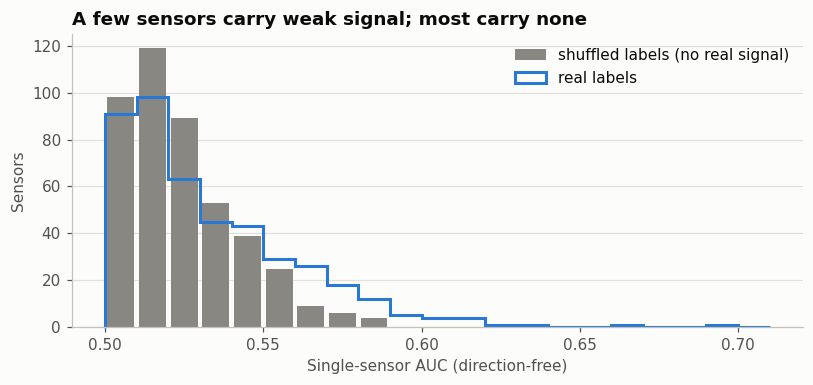

In [ ]:
def direction_free_auc(labels, frame):
    auc = frame.apply(lambda col: roc_auc_score(labels, col))
    return np.maximum(auc, 1 - auc)      # 0.5 = no signal, 1.0 = perfect separation

auc_real = direction_free_auc(y, X_filled)
auc_null = direction_free_auc(np.random.default_rng(RANDOM_SEED).permutation(y), X_filled)
print(f"Single-sensor AUC, real labels:     median {auc_real.median():.3f}, best {auc_real.max():.3f}; "
      f"{(auc_real > 0.6).sum()} sensors above 0.60")
print(f"Single-sensor AUC, shuffled labels: median {auc_null.median():.3f}, best {auc_null.max():.3f}; "
      f"{(auc_null > 0.6).sum()} sensors above 0.60")

time_rank = pd.Series(np.arange(len(y)), index=X_filled.index)
top = auc_real.sort_values(ascending=False).head(8)
display(pd.DataFrame({"AUC": top.round(3),
                      "Spearman correlation with time": [round(X_filled[s].corr(time_rank, method="spearman"), 2)
                                                         for s in top.index]}))
print(f"Time order alone separates fail from pass with AUC {roc_auc_score(y, -time_rank):.3f}: early wafers fail more often.")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
bins = np.linspace(0.5, 0.71, 22)
ax.hist(auc_null, bins=bins, color=MUTED, rwidth=0.85, label="shuffled labels (no real signal)")
ax.hist(auc_real, bins=bins, histtype="step", color=BLUE, linewidth=2, label="real labels")
ax.set_xlabel("Single-sensor AUC (direction-free)")
ax.set_ylabel("Sensors")
ax.set_title("A few sensors carry weak signal; most carry none")
ax.legend()
plt.tight_layout()
plt.show()

**Finding.** The signal is weak and concentrated in a few sensors. The typical sensor separates fail from pass no better than chance (median AUC 0.524, vs 0.520 with shuffled labels). Twelve sensors exceed 0.60, which never happens with shuffled labels, and the best reaches 0.692. Several of the strongest sensors also drift over time (Spearman ρ between −0.52 and +0.59), and time order alone reaches AUC 0.636. Part of what these sensors say about failure may simply be *when* a wafer was made.

**Decision.** Expect modest performance, an AUC near 0.7 rather than 0.9. Keep all sensors and let each model weigh them; hand-picking sensors on all wafers would leak labels. With only 104 failures, fully grown trees can memorize individual failures, so the forest's leaf size is tuned. The time-ordered check (E5) matters for both models.

### 3.6 EDA summary: finding → decision

| Finding | Logistic regression | Random forest |
|---|---|---|
| 6.6% failures; rate falls from 22% (Jul) to 3% (Sep) | Balanced accuracy and cost per wafer; no class weights; time check (E5) | Same |
| 32 sensors >40% missing, 116 constant | Dropped once before modeling (442 remain) | Same |
| Small remaining gaps | Median imputation inside the pipeline | Same |
| Scales over 8 orders of magnitude; heavy skew; readings up to 40 SD | Quantile transform (E3), compared with plain standardizing (E2) | Nothing: splits depend only on order |
| 303 sensors with a near-twin | L2 penalty, C tuned by inner CV | Nothing; importance read with care |
| Weak signal in about a dozen sensors; 104 failures | Expect AUC near 0.7 | Tune leaf size; calibrate risks |

## 4. The two models
Cleaning happened once in 3.2. Everything else that learns from data is fitted on each training fold only.

**Logistic regression:** median imputer → standardize (E2) or quantile transform (E3) → L2 logistic regression. The imputer and transform are fitted once on the training fold; then `GridSearchCV` picks C by inner 5-fold CV on **log-loss**, which rewards honest probabilities. (Fitting the transform once, rather than inside every inner fold and every C, makes this about 8 times faster. The inner validation wafers share the training fold's medians and quantiles, which use no labels; the outer test fold is never touched.)

**Random forest:** median imputer → 200 trees, with no scaling. Two extra steps make its risks usable with the cost threshold:
- **Out-of-bag (OOB) predictions.** Each tree is grown on a bootstrap sample, so every training wafer is left out of about a third of the trees. Those trees' vote is the wafer's OOB risk: an honest held-out prediction that costs no extra fitting.
- **Calibration.** A forest's raw score is the share of trees voting "fail", not a probability. A Platt step (a one-input logistic regression) fitted on the OOB risks turns it into one.
- **Tuning.** Each leaf size in `LEAF_SIZES` is scored by the log-loss of its calibrated OOB risks, and the best is kept. This is about 10 times cheaper than wrapping the forest in `GridSearchCV` and `CalibratedClassifierCV`, for the same purpose.

Both models follow the same pattern: a `fit_...` function returns the fitted pieces in a dictionary, and a `..._risk` function turns new wafers into risks. The threshold needs no tuning: it comes from the cost ratio.

In [ ]:
X = X_raw.loc[:, kept]                      # the 442 sensors kept in 3.2 (constant and mostly-missing ones dropped)
print(f"Modeling data: {X.shape[0]} wafers x {X.shape[1]} sensors, {y.sum()} failures")


def fit_logreg(X_train, y_train, transform):
    """Median-fill gaps and put every sensor on a common scale, then L2 logistic regression with C tuned on log-loss.
    transform: "standard" (E2) or "quantile" (E3). Returns the fitted preprocessing and the C search."""
    if transform == "quantile":
        scale = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=RANDOM_SEED)
    else:
        scale = StandardScaler()
    prep = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True), scale).fit(X_train)
    search = GridSearchCV(LogisticRegression(max_iter=5000), {"C": C_GRID}, scoring="neg_log_loss", n_jobs=-1,
                          cv=StratifiedKFold(N_SPLITS, shuffle=True, random_state=RANDOM_SEED), return_train_score=True)
    search.fit(prep.transform(X_train), y_train)
    return {"prep": prep, "search": search}


def logreg_risk(model, X_new):
    """Predicted risk of failure."""
    return model["search"].predict_proba(model["prep"].transform(X_new))[:, 1]


def fit_forest(X_train, y_train):
    """Try each leaf size; keep the forest whose calibrated out-of-bag risks have the lowest log-loss.
    Returns a dict with the fitted forest, its Platt calibrator, the chosen leaf size and the loss per leaf size."""
    best, curve = None, {}
    for leaf in LEAF_SIZES:
        rf = make_pipeline(SimpleImputer(strategy="median", keep_empty_features=True),
                           RandomForestClassifier(n_estimators=N_TREES, min_samples_leaf=leaf, oob_score=True,
                                                  n_jobs=-1, random_state=RANDOM_SEED))
        rf.fit(X_train, y_train)
        oob = rf[-1].oob_decision_function_[:, [1]]           # each wafer's vote share from trees that never saw it
        platt = LogisticRegression(C=1e6, max_iter=1000).fit(oob, y_train)     # vote share -> probability
        oob_loss = log_loss(y_train, platt.predict_proba(oob)[:, 1])
        train_loss = log_loss(y_train, platt.predict_proba(rf.predict_proba(X_train)[:, [1]])[:, 1])
        curve[leaf] = {"train": train_loss, "out-of-bag": oob_loss}
        if best is None or oob_loss < best["loss"]:
            best = {"rf": rf, "platt": platt, "leaf": leaf, "loss": oob_loss}
    best["curve"] = curve
    return best


def forest_risk(forest, X_new, calibrated=True):
    """Calibrated risk of failure, or the raw vote share if calibrated=False."""
    raw = forest["rf"].predict_proba(X_new)[:, [1]]
    return forest["platt"].predict_proba(raw)[:, 1] if calibrated else raw[:, 0]


def decision_metrics(y_true, risk, threshold=THRESHOLD, cost_fn=COST_FN, cost_fp=COST_FP):
    flagged = (risk >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return {"balanced_accuracy": balanced_accuracy_score(y_true, flagged),
            "recall": tp / (tp + fn),
            "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "flag_rate": (tp + fp) / len(y_true),
            "cost_per_wafer": (cost_fn * fn + cost_fp * fp) / len(y_true)}


def ranking_metrics(y_true, risk):
    return {"roc_auc": roc_auc_score(y_true, risk), "pr_auc": average_precision_score(y_true, risk)}

Modeling data: 1567 wafers x 442 sensors, 104 failures


**What the quantile transform does to one sensor.** The sensor with the most extreme reading, before and after. The transform is fitted on all wafers here for illustration only; in the model it is fitted on each training fold.

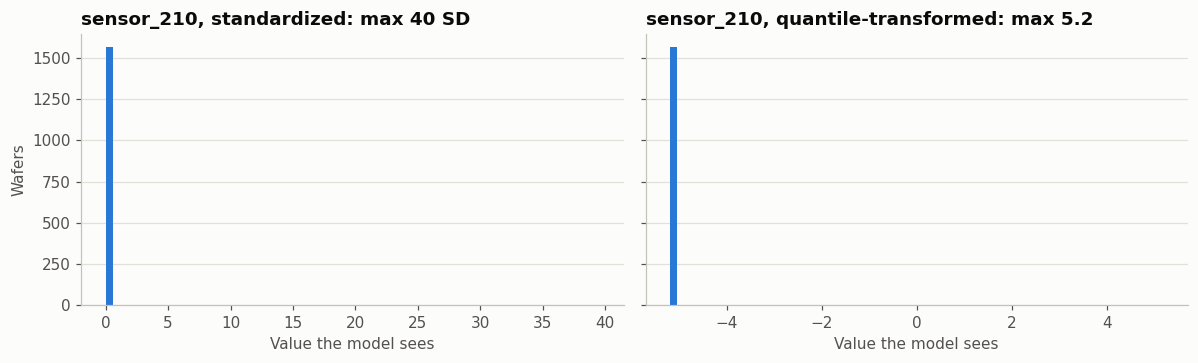

In [ ]:
demo = max_abs_z.idxmax()
raw_z = z[demo]
quantile_z = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit_transform(X_filled[[demo]])[:, 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, values, title in ((axes[0], raw_z, f"{demo}, standardized: max {raw_z.abs().max():.0f} SD"),
                          (axes[1], quantile_z, f"{demo}, quantile-transformed: max {np.abs(quantile_z).max():.1f}")):
    ax.hist(values, bins=60, color=BLUE, rwidth=0.85)
    ax.set_title(title)
    ax.set_xlabel("Value the model sees")
axes[0].set_ylabel("Wafers")
plt.tight_layout()
plt.show()

## 5. Nested repeated cross-validation
The outer loop splits the wafers into 5 stratified folds (about 21 failures each) and repeats this with 5 different shuffles. On each of the 25 outer folds, all models are fitted on the same training wafers and score the same held-out wafers once. Every wafer therefore gets one held-out risk per repeat and per model.

The loop stores risks only. Thresholds, and the forest's raw vs calibrated score, are compared afterwards from the stored risks, with no refitting.

In [ ]:
splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS,
                                      random_state=RANDOM_SEED).split(X, y))
risk = {key: np.full((N_REPEATS, len(y)), np.nan) for key in ("E1", "E2", "E3", "E4 raw", "E4")}
fold_log = []                                  # what each fold's models chose, for Sections 7 and 10

start = time.time()
for i, (train, test) in enumerate(splits):
    rep = i // N_SPLITS
    X_train, y_train, X_test = X.iloc[train], y[train], X.iloc[test]

    risk["E1"][rep, test] = y_train.mean()                          # majority baseline: the training failure rate

    lr_standard = fit_logreg(X_train, y_train, "standard")
    risk["E2"][rep, test] = logreg_risk(lr_standard, X_test)

    lr_quantile = fit_logreg(X_train, y_train, "quantile")
    risk["E3"][rep, test] = logreg_risk(lr_quantile, X_test)

    forest = fit_forest(X_train, y_train)
    risk["E4 raw"][rep, test] = forest_risk(forest, X_test, calibrated=False)
    risk["E4"][rep, test] = forest_risk(forest, X_test)

    fold_log.append({
        "C_E2": lr_standard["search"].best_params_["C"],
        "C_E3": lr_quantile["search"].best_params_["C"],
        "lr_curves": {name: (-lr["search"].cv_results_["mean_train_score"], -lr["search"].cv_results_["mean_test_score"])
                      for name, lr in (("E2", lr_standard), ("E3", lr_quantile))},
        "coef_E3": pd.Series(lr_quantile["search"].best_estimator_.coef_[0], index=X.columns),
        "leaf": forest["leaf"],
        "rf_curve": forest["curve"],
        "importance": pd.Series(forest["rf"][-1].feature_importances_, index=X.columns),
    })
    if (i + 1) % N_SPLITS == 0:
        print(f"Repeat {rep + 1} of {N_REPEATS} done, {time.time() - start:.0f}s so far")

assert all(not np.isnan(r).any() for r in risk.values())

Repeat 1 of 5 done, 117s so far
Repeat 2 of 5 done, 227s so far
Repeat 3 of 5 done, 339s so far
Repeat 4 of 5 done, 450s so far
Repeat 5 of 5 done, 560s so far


## 6. Results on the same 25 outer folds
Mean ± standard deviation across the 25 outer folds. Cost per wafer is in false-alarm units: always passing costs 10 for every failure, so the baseline pays about 0.66 per wafer. The lower block reuses the same fits to show what the threshold and calibration contribute.

,Balanced acc.,Recall (fail),Specificity,Precision (fail),Flag rate,Cost / wafer,ROC-AUC,PR-AUC
E1 Majority baseline,0.500 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.664 ± 0.013,0.500 ± 0.000,0.066 ± 0.001
"E2 Logistic regression, standardized",0.599 ± 0.039,0.333 ± 0.083,0.866 ± 0.044,0.161 ± 0.057,0.147 ± 0.044,0.568 ± 0.056,0.687 ± 0.044,0.156 ± 0.041
"E3 Logistic regression, quantile",0.633 ± 0.048,0.450 ± 0.102,0.816 ± 0.029,0.149 ± 0.032,0.201 ± 0.030,0.537 ± 0.065,0.695 ± 0.056,0.180 ± 0.042
"E4 Random forest, calibrated",0.646 ± 0.051,0.442 ± 0.108,0.850 ± 0.030,0.175 ± 0.040,0.170 ± 0.031,0.510 ± 0.068,0.742 ± 0.043,0.189 ± 0.034
E2 at threshold 0.5,0.502 ± 0.012,0.010 ± 0.024,0.995 ± 0.005,0.095 ± 0.251,0.006 ± 0.005,0.662 ± 0.019,0.687 ± 0.044,0.156 ± 0.041
E3 at threshold 0.5,0.502 ± 0.007,0.004 ± 0.014,1.000 ± 0.001,0.080 ± 0.277,0.000 ± 0.001,0.661 ± 0.017,0.695 ± 0.056,0.180 ± 0.042
E4 at threshold 0.5,0.500 ± 0.005,0.002 ± 0.010,0.999 ± 0.003,0.040 ± 0.200,0.001 ± 0.002,0.664 ± 0.014,0.742 ± 0.043,0.189 ± 0.034
E4 raw vote share (no calibration),0.666 ± 0.046,0.534 ± 0.098,0.797 ± 0.024,0.158 ± 0.024,0.225 ± 0.025,0.498 ± 0.059,0.742 ± 0.043,0.189 ± 0.034


E2 Logistic regression, standardized   beats the baseline in 25/25 folds on balanced accuracy, 25/25 on cost
E3 Logistic regression, quantile       beats the baseline in 24/25 folds on balanced accuracy, 24/25 on cost
E4 Random forest, calibrated           beats the baseline in 25/25 folds on balanced accuracy, 25/25 on cost
E3 has lower cost than E2 in 17/25 folds (effect of the quantile transform)
E4 has lower cost than E3 in 18/25 folds (forest vs best linear model)

Why weighted precision misleads: the always-pass baseline scores 0.872 on it while catching no failures.


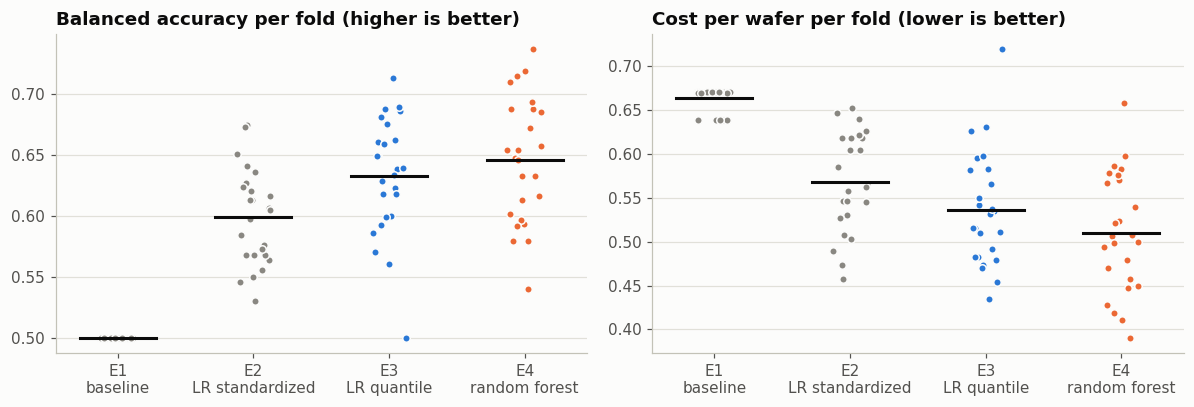

Dots: the 25 outer folds. Black bars: means.


In [ ]:
MAIN = {"E1 Majority baseline":                       ("E1", THRESHOLD),
        "E2 Logistic regression, standardized":       ("E2", THRESHOLD),
        "E3 Logistic regression, quantile":           ("E3", THRESHOLD),
        "E4 Random forest, calibrated":               ("E4", THRESHOLD)}
SUPPORT = {"E2 at threshold 0.5":                     ("E2", 0.5),
           "E3 at threshold 0.5":                     ("E3", 0.5),
           "E4 at threshold 0.5":                     ("E4", 0.5),
           "E4 raw vote share (no calibration)":      ("E4 raw", THRESHOLD)}
LABELS = {"balanced_accuracy": "Balanced acc.", "recall": "Recall (fail)", "specificity": "Specificity",
          "precision": "Precision (fail)", "flag_rate": "Flag rate", "cost_per_wafer": "Cost / wafer",
          "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}


def fold_results(experiments):
    """One row per experiment and outer fold."""
    rows = []
    for name, (key, thr) in experiments.items():
        for i, (train, test) in enumerate(splits):
            r = risk[key][i // N_SPLITS, test]
            rows.append({"experiment": name, "fold": i, **decision_metrics(y[test], r, thr), **ranking_metrics(y[test], r)})
    return pd.DataFrame(rows)


def mean_sd_table(results):
    stats = results.groupby("experiment", sort=False)[list(LABELS)].agg(["mean", "std"])
    table = pd.DataFrame({LABELS[m]: stats[(m, "mean")].map("{:.3f}".format) + " ± " + stats[(m, "std")].map("{:.3f}".format)
                          for m in LABELS})
    table.index.name = None
    return table


results = fold_results({**MAIN, **SUPPORT})
display(mean_sd_table(results))

cost = results.pivot(index="fold", columns="experiment", values="cost_per_wafer")
bal = results.pivot(index="fold", columns="experiment", values="balanced_accuracy")
names = list(MAIN)
for name in names[1:]:
    print(f"{name:<38} beats the baseline in {(bal[name] > bal[names[0]]).sum():>2}/{len(splits)} folds on balanced accuracy, "
          f"{(cost[name] < cost[names[0]]).sum():>2}/{len(splits)} on cost")
print(f"E3 has lower cost than E2 in {(cost[names[2]] < cost[names[1]]).sum()}/{len(splits)} folds (effect of the quantile transform)")
print(f"E4 has lower cost than E3 in {(cost[names[3]] < cost[names[2]]).sum()}/{len(splits)} folds (forest vs best linear model)")

weighted = [precision_score(y[test], np.zeros(len(test), int), average="weighted", zero_division=0) for _, test in splits]
print(f"\nWhy weighted precision misleads: the always-pass baseline scores {np.mean(weighted):.3f} on it while catching no failures.")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, table, title in ((axes[0], bal, "Balanced accuracy per fold (higher is better)"),
                         (axes[1], cost, "Cost per wafer per fold (lower is better)")):
    for k, name in enumerate(names):
        vals = table[name].to_numpy()
        jitter = np.random.default_rng(k).uniform(-0.13, 0.13, len(vals))
        ax.scatter(k + jitter, vals, s=24, color=[MUTED, MUTED, BLUE, ORANGE][k], edgecolor=SURFACE, linewidth=1, zorder=3)
        ax.plot([k - 0.28, k + 0.28], [vals.mean()] * 2, color=INK, linewidth=2, zorder=4)
    ax.set_xticks(range(len(names)), ["E1\nbaseline", "E2\nLR standardized", "E3\nLR quantile", "E4\nrandom forest"])
    ax.set_title(title)
plt.tight_layout()
plt.show()
print("Dots: the 25 outer folds. Black bars: means.")

**✍ After running: reading the results.**
- **Threshold 0.5 (lower block):** how many wafers does each model flag? With 6.6% failures, few reach 50% risk. This is the Kaggle notebook's setting.
- **E2 → E3:** did the quantile transform lower cost in most folds? Did ROC-AUC change, or only the decisions?
- **E4 raw vs calibrated:** calibration can't change ROC-AUC (it preserves the order of wafers), only how many cross 0.091.
- **E3 vs E4:** does the forest's nonlinearity pay off on ranking (ROC-AUC), on decisions (cost), or neither?
- **Spread:** with about 21 failures per fold, how wide is the fold-to-fold range?

## 7. Are the risks honest? Calibration and validation curves
The cost rule assumes a predicted risk of 9% really means about a 9% chance of failure. The left chart checks that on the held-out wafers. The two charts on the right are **validation curves**: training vs validation log-loss across each model's complexity setting, computed inside the training folds only. A widening gap means overfitting.

Baseline                    held-out log-loss 0.2442 | Brier 0.0620 | mean risk 6.6% (actual 6.6%)
E2 LR standardized          held-out log-loss 0.2572 | Brier 0.0640 | mean risk 6.9% (actual 6.6%)
E3 LR quantile              held-out log-loss 0.2289 | Brier 0.0598 | mean risk 6.5% (actual 6.6%)
E4 forest, raw vote share   held-out log-loss 0.2237 | Brier 0.0592 | mean risk 6.9% (actual 6.6%)
E4 forest, calibrated       held-out log-loss 0.2254 | Brier 0.0598 | mean risk 6.6% (actual 6.6%)

C chosen, E2: {'3e-03': 17, '1e-03': 8}
C chosen, E3: {'3e-03': 23, '1e-03': 2}
Leaf size chosen, E4: {1: 1, 3: 2, 10: 13, 30: 9}


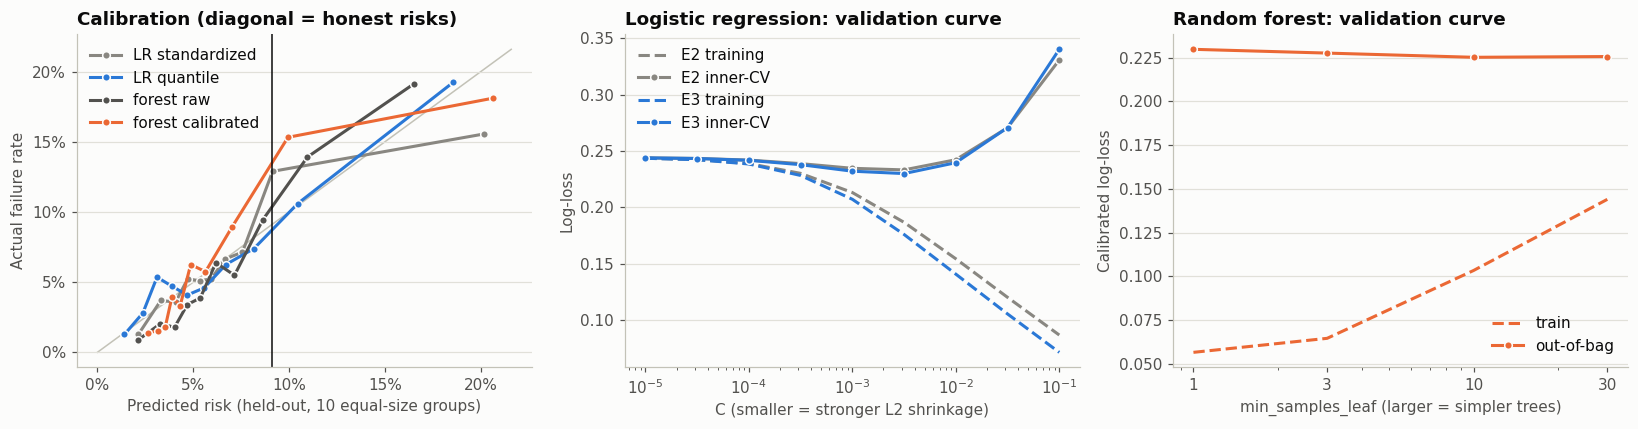

In [ ]:
y_all = np.tile(y, N_REPEATS)                  # every wafer once per repeat
for key, label in (("E1", "Baseline"), ("E2", "E2 LR standardized"), ("E3", "E3 LR quantile"),
                   ("E4 raw", "E4 forest, raw vote share"), ("E4", "E4 forest, calibrated")):
    r = np.clip(risk[key].ravel(), 1e-6, 1 - 1e-6)
    print(f"{label:<27} held-out log-loss {log_loss(y_all, r):.4f} | Brier {brier_score_loss(y_all, r):.4f} | "
          f"mean risk {r.mean():.1%} (actual {y.mean():.1%})")

C_E2 = pd.Series([f["C_E2"] for f in fold_log])
C_E3 = pd.Series([f["C_E3"] for f in fold_log])
leaf = pd.Series([f["leaf"] for f in fold_log])
print("\nC chosen, E2:", C_E2.map("{:.0e}".format).value_counts().to_dict())
print("C chosen, E3:", C_E3.map("{:.0e}".format).value_counts().to_dict())
print("Leaf size chosen, E4:", leaf.value_counts().sort_index().to_dict())
edge = sum((C_E2 == C_GRID[0]) | (C_E2 == C_GRID[-1])) + sum((C_E3 == C_GRID[0]) | (C_E3 == C_GRID[-1]))
if edge:
    print(f"Note: C landed on the edge of C_GRID in {edge} of 50 fits; consider widening the grid.")

fig, (axa, axb, axc) = plt.subplots(1, 3, figsize=(15, 4))
for key, label, color in (("E2", "LR standardized", MUTED), ("E3", "LR quantile", BLUE),
                          ("E4 raw", "forest raw", INK_2), ("E4", "forest calibrated", ORANGE)):
    frac_fail, mean_risk = calibration_curve(y_all, risk[key].ravel(), n_bins=10, strategy="quantile")
    axa.plot(mean_risk, frac_fail, "o-", color=color, markersize=5, markeredgecolor=SURFACE, label=label)
lim = max(axa.get_xlim()[1], axa.get_ylim()[1])
axa.plot([0, lim], [0, lim], color=AXIS, linewidth=1, zorder=0)
axa.axvline(THRESHOLD, color=INK, linewidth=1)
axa.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axa.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axa.set_xlabel("Predicted risk (held-out, 10 equal-size groups)")
axa.set_ylabel("Actual failure rate")
axa.set_title("Calibration (diagonal = honest risks)")
axa.legend(loc="upper left")

for key, color in (("E2", MUTED), ("E3", BLUE)):
    train_curve = np.mean([f["lr_curves"][key][0] for f in fold_log], axis=0)
    valid_curve = np.mean([f["lr_curves"][key][1] for f in fold_log], axis=0)
    axb.plot(C_GRID, train_curve, "--", color=color, label=f"{key} training")
    axb.plot(C_GRID, valid_curve, "o-", color=color, markersize=5, markeredgecolor=SURFACE, label=f"{key} inner-CV")
axb.set_xscale("log")
axb.set_xlabel("C (smaller = stronger L2 shrinkage)")
axb.set_ylabel("Log-loss")
axb.set_title("Logistic regression: validation curve")
axb.legend()

for part, style in (("train", "--"), ("out-of-bag", "o-")):
    values = [np.mean([f["rf_curve"][l][part] for f in fold_log]) for l in LEAF_SIZES]
    axc.plot(LEAF_SIZES, values, style, color=ORANGE, markersize=5, markeredgecolor=SURFACE, label=part)
axc.set_xscale("log")
axc.set_xticks(LEAF_SIZES, [str(l) for l in LEAF_SIZES])
axc.set_xlabel("min_samples_leaf (larger = simpler trees)")
axc.set_ylabel("Calibrated log-loss")
axc.set_title("Random forest: validation curve")
axc.legend()
plt.tight_layout()
plt.show()

**✍ After running.** Which curves sit on the diagonal near the 0.091 line? The forest's raw vote share usually doesn't, which is why it is calibrated. In the validation curves, where does validation log-loss bottom out, and how far below it does training log-loss fall? A forest with leaf size 1 typically fits the training wafers almost perfectly, which is the overfitting the Kaggle notebook's train-vs-test accuracy plot was getting at.

## 8. Confusion matrices and the threshold
Counts are for all 1,567 wafers, each scored once by a model that never saw it, averaged over the 5 repeats.

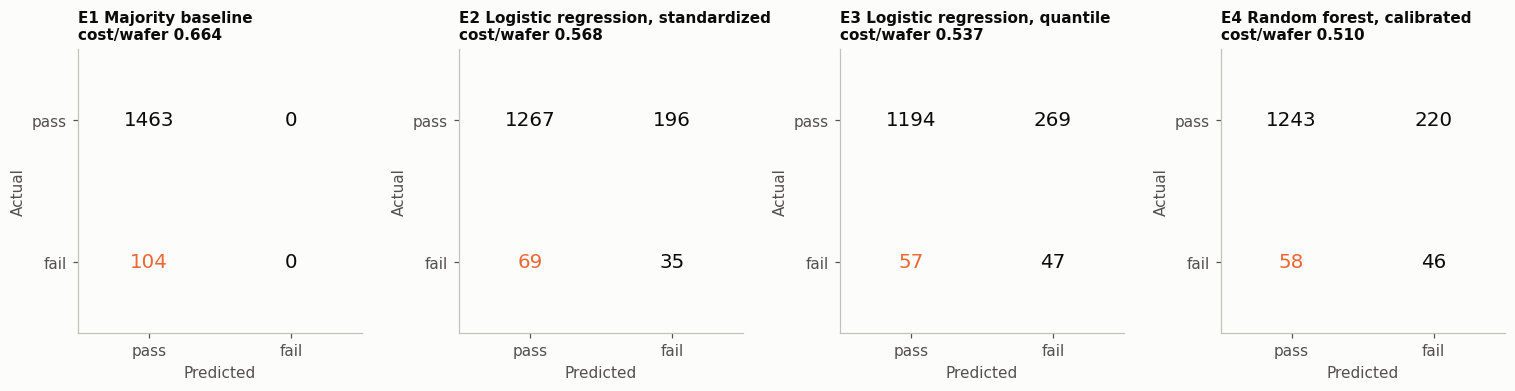

Orange: missed failures, the expensive error.


In [ ]:
def pooled_confusion(key, threshold):
    """Average confusion matrix over the repeats; each repeat scores every wafer once."""
    return sum(confusion_matrix(y, (risk[key][r] >= threshold).astype(int), labels=[0, 1])
               for r in range(N_REPEATS)) / N_REPEATS


def draw_confusion(ax, cm, title):
    ax.imshow(cm, cmap=ListedColormap([SURFACE]), vmin=0, vmax=1)
    for (row, col), value in np.ndenumerate(cm):
        ax.text(col, row, f"{value:.0f}", ha="center", va="center", fontsize=13,
                color=ORANGE if (row, col) == (1, 0) else INK)
    ax.set_xticks([0, 1], ["pass", "fail"])
    ax.set_yticks([0, 1], ["pass", "fail"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(title, fontsize=10)
    ax.grid(False)


def cost_of(cm):
    return (COST_FN * cm[1, 0] + COST_FP * cm[0, 1]) / cm.sum()


fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, (key, thr)) in zip(axes, MAIN.items()):
    cm = pooled_confusion(key, thr)
    draw_confusion(ax, cm, f"{name}\ncost/wafer {cost_of(cm):.3f}")
plt.tight_layout()
plt.show()
print("Orange: missed failures, the expensive error.")

**Threshold explorer.** Move the slider to see how both models' errors trade off. This is descriptive only: the threshold used everywhere else comes from the cost ratio, not from this chart. The curve underneath shows cost per wafer at every threshold.

interactive(children=(FloatSlider(value=0.091, continuous_update=False, description='threshold', max=0.5, min=…

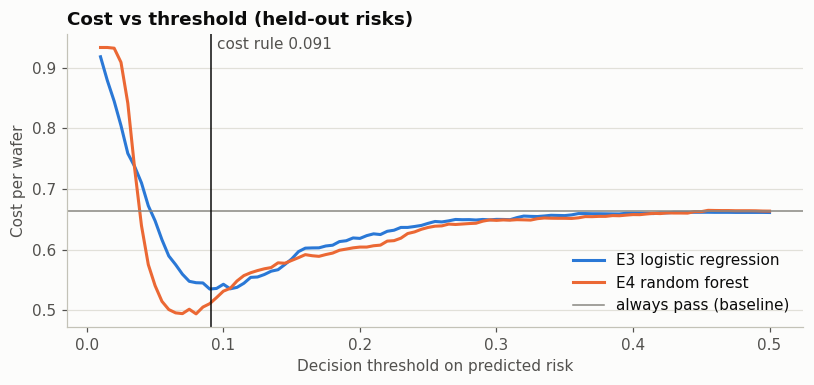

In [ ]:
def show_threshold(threshold=THRESHOLD):
    fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
    for ax, key, name in ((axes[0], "E3", "Logistic regression (E3)"), (axes[1], "E4", "Random forest (E4)")):
        cm = pooled_confusion(key, threshold)
        draw_confusion(ax, cm, f"{name}, threshold {threshold:.3f}\ncost/wafer {cost_of(cm):.3f}")
    plt.tight_layout()
    plt.show()


try:
    from ipywidgets import interact, FloatSlider
    interact(show_threshold, threshold=FloatSlider(value=round(THRESHOLD, 3), min=0.02, max=0.5, step=0.005,
                                                   readout_format=".3f", continuous_update=False))
except ImportError:                              # no widgets available: show the cost rule and the default 0.5
    show_threshold(THRESHOLD)
    show_threshold(0.5)

thresholds = np.round(np.arange(0.01, 0.5001, 0.005), 3)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for key, label, color in (("E3", "E3 logistic regression", BLUE), ("E4", "E4 random forest", ORANGE)):
    ax.plot(thresholds, [cost_of(pooled_confusion(key, t)) for t in thresholds], color=color, label=label)
ax.axhline(COST_FN * y.mean(), color=MUTED, linewidth=1, label="always pass (baseline)")
ax.axvline(THRESHOLD, color=INK, linewidth=1)
ax.annotate(f"cost rule {THRESHOLD:.3f}", (THRESHOLD, ax.get_ylim()[1]), xytext=(4, -2), textcoords="offset points",
            va="top", color=INK_2)
ax.set_xlabel("Decision threshold on predicted risk")
ax.set_ylabel("Cost per wafer")
ax.set_title("Cost vs threshold (held-out risks)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**✍ After running.** Is the lowest point of each cost curve close to 0.091? If a model's risks are honest, it should be. How do the two models' errors differ at the cost rule: does one trade more false alarms for fewer misses?

## 9. Time-ordered check (E5)
Random CV mixes early and late wafers, so a model can learn period-specific patterns and be tested on the same period. Here E3 and E4, fixed before seeing any results, train on the earliest 80% of wafers (with their own tuning and calibration done on those wafers only) and are tested once on the latest 20%.

In [ ]:
early, late = np.arange(n_early), np.arange(n_early, len(y))
print(f"Train (early): {timestamp.iloc[0]:%d %b} to {timestamp.iloc[n_early - 1]:%d %b}, {len(early)} wafers, "
      f"{y[early].sum()} failures ({y[early].mean():.1%})")
print(f"Test (late):   {timestamp.iloc[n_early]:%d %b} to {timestamp.iloc[-1]:%d %b}, {len(late)} wafers, "
      f"{y[late].sum()} failures ({y[late].mean():.1%})")

late_risk = {"E1 baseline": np.full(len(late), y[early].mean()),
             "E3 logistic regression": logreg_risk(fit_logreg(X.iloc[early], y[early], "quantile"), X.iloc[late]),
             "E4 random forest": forest_risk(fit_forest(X.iloc[early], y[early]), X.iloc[late])}

cv_means = results.groupby("experiment")[list(LABELS)].mean()
rows = {"E3, random CV (mean of 25 folds)": cv_means.loc["E3 Logistic regression, quantile"],
        "E4, random CV (mean of 25 folds)": cv_means.loc["E4 Random forest, calibrated"]}
for name, r in late_risk.items():
    rows[f"{name}, late wafers"] = pd.Series({**decision_metrics(y[late], r), **ranking_metrics(y[late], r)})
time_table = pd.DataFrame(rows).T[list(LABELS)].rename(columns=LABELS).astype(float).round(3)
display(time_table)
for name, r in list(late_risk.items())[1:]:
    flagged = r >= THRESHOLD
    print(f"{name}: mean predicted risk {r.mean():.1%} vs actual {y[late].mean():.1%}; {flagged.sum()} of {len(late)} "
          f"flagged, catching {(flagged & (y[late] == 1)).sum()} of {y[late].sum()} failures")

Train (early): 19 Jul to 02 Oct, 1254 wafers, 87 failures (6.9%)
Test (late):   02 Oct to 17 Oct, 313 wafers, 17 failures (5.4%)


,Balanced acc.,Recall (fail),Specificity,Precision (fail),Flag rate,Cost / wafer,ROC-AUC,PR-AUC
"E3, random CV (mean of 25 folds)",0.633,0.450,0.816,0.149,0.201,0.537,0.695,0.180
"E4, random CV (mean of 25 folds)",0.646,0.442,0.850,0.175,0.170,0.510,0.742,0.189
"E1 baseline, late wafers",0.500,0.000,1.000,0.000,0.000,0.543,0.500,0.054
"E3 logistic regression, late wafers",0.570,0.176,0.963,0.214,0.045,0.482,0.675,0.146
"E4 random forest, late wafers",0.514,0.176,0.851,0.064,0.150,0.588,0.549,0.071


E3 logistic regression: mean predicted risk 5.5% vs actual 5.4%; 14 of 313 flagged, catching 3 of 17 failures
E4 random forest: mean predicted risk 7.0% vs actual 5.4%; 47 of 313 flagged, catching 3 of 17 failures


**✍ After running.** Does the ranking transfer (late-wafer ROC-AUC close to random CV)? Does the risk scale transfer (mean predicted risk close to the actual late failure rate)? If ranking holds but the scale drifts, the fix is recalibrating on recent wafers. Which model is more sensitive to the period? With only about 17 failures in the late period, each one moves recall by about 6 points, so treat these as rough.

## 10. Error analysis
Uses each wafer's held-out risk averaged over the 5 repeats, so every wafer is judged by models that never saw it.

### 10.1 Which sensors each model relies on
- **Logistic regression:** the E3 coefficients, averaged over the 25 fold models. On the quantile scale every sensor has the same spread, so coefficient sizes are comparable.
- **Random forest:** impurity importance, averaged over the 25 fold models. It is computed on training wafers and split between near-copies, so read it as "what the forest leans on", not proof of a sensor's effect.

Sensors in both models' top 15: 7 (sensor_60, sensor_104, sensor_511, sensor_478, sensor_22, sensor_206, sensor_342)


,LR coefficient (mean),LR in top 15 (of 25 folds),RF importance (mean),RF in top 15 (of 25 folds),single-sensor AUC (3.5),Spearman with time
sensor_60,0.0791,25,0.0315,25,0.6924,-0.4421
sensor_489,-0.0634,25,0.0021,0,0.5547,-0.0454
sensor_130,0.0596,24,0.0033,0,0.6192,-0.3103
sensor_34,0.0572,23,0.0034,1,0.6106,-0.1482
sensor_104,0.0554,24,0.0121,24,0.6682,-0.5236
sensor_486,-0.0539,19,0.0017,0,0.5342,-0.0367
sensor_511,0.0523,23,0.0094,14,0.6361,-0.4154
sensor_478,0.0503,24,0.0087,15,0.6214,-0.2187
sensor_22,0.0496,17,0.0079,13,0.6025,0.2010
sensor_206,0.0490,22,0.0114,21,0.6193,-0.2107


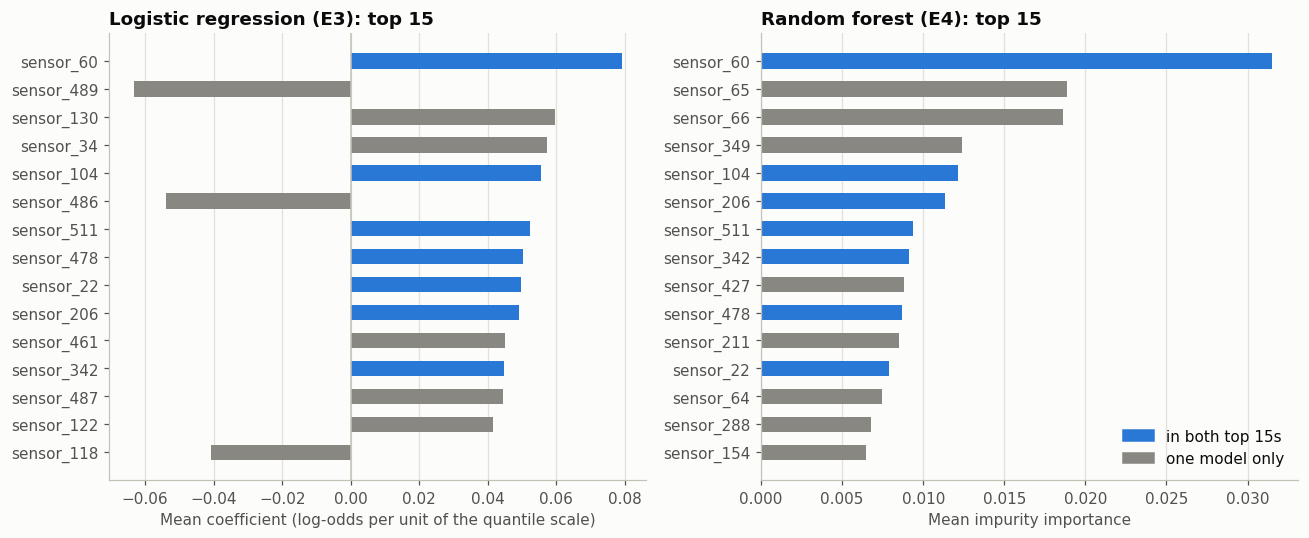

In [ ]:
coef = pd.concat([f["coef_E3"] for f in fold_log], axis=1)
imp = pd.concat([f["importance"] for f in fold_log], axis=1)
lr_top = coef.mean(axis=1).abs().nlargest(15).index
rf_top = imp.mean(axis=1).nlargest(15).index
shared = lr_top.intersection(rf_top)
print(f"Sensors in both models' top 15: {len(shared)} ({', '.join(shared) if len(shared) else 'none'})")

time_rank = pd.Series(np.arange(len(y)), index=X.index)
union = lr_top.union(rf_top, sort=False)
importance_table = pd.DataFrame({
    "LR coefficient (mean)": coef.mean(axis=1)[union],
    "LR in top 15 (of 25 folds)": (coef.abs().rank(ascending=False) <= 15).sum(axis=1)[union],
    "RF importance (mean)": imp.mean(axis=1)[union],
    "RF in top 15 (of 25 folds)": (imp.rank(ascending=False) <= 15).sum(axis=1)[union],
    "single-sensor AUC (3.5)": auc_real.reindex(union),
    "Spearman with time": [X[s].corr(time_rank, method="spearman") for s in union],
})
display(importance_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, values, title, xlabel in ((axes[0], coef.mean(axis=1)[lr_top][::-1], "Logistic regression (E3): top 15",
                                   "Mean coefficient (log-odds per unit of the quantile scale)"),
                                  (axes[1], imp.mean(axis=1)[rf_top][::-1], "Random forest (E4): top 15",
                                   "Mean impurity importance")):
    ax.barh(values.index, values.to_numpy(), height=0.55,
            color=[BLUE if s in shared else MUTED for s in values.index])
    ax.axvline(0, color=AXIS, linewidth=1)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
axes[1].legend(handles=[Patch(color=BLUE, label="in both top 15s"), Patch(color=MUTED, label="one model only")],
               loc="lower right")
plt.tight_layout()
plt.show()

**✍ After running.** Do the models agree on the main sensors? Are those the strongest single sensors from 3.5? How many drift with time (|Spearman| above about 0.3)? Those may stand in for *when* a wafer was made.

### 10.2 Which failures get caught, and where the models disagree

In [ ]:
avg = {"LR": risk["E3"].mean(axis=0), "RF": risk["E4"].mean(axis=0)}
flag = {m: avg[m] >= THRESHOLD for m in avg}
jul_aug = timestamp.dt.month.isin([7, 8]).to_numpy()            # the high-failure period in 3.1

wafers = pd.DataFrame({
    "date": timestamp.dt.strftime("%d %b"),
    "actual": np.where(y == 1, "fail", "pass"),
    "LR risk": avg["LR"], "RF risk": avg["RF"],
    "missing share": X.isna().mean(axis=1).to_numpy(),
    "readings beyond 3 SD": (z.abs() > EXTREME_SD).sum(axis=1).to_numpy(),     # z from 3.3, description only
    "Jul-Aug": jul_aug,
})

rows = []
for m in ("LR", "RF"):
    outcome = np.select([(y == 1) & flag[m], (y == 1) & ~flag[m], (y == 0) & flag[m]],
                        ["caught failure", "missed failure", "false alarm"], default="correct pass")
    for o in ("caught failure", "missed failure", "false alarm", "correct pass"):
        sel = wafers[outcome == o]
        rows.append({"model": m, "outcome": o, "wafers": len(sel), "mean risk": sel[f"{m} risk"].mean(),
                     "missing share": sel["missing share"].mean(),
                     "readings beyond 3 SD": sel["readings beyond 3 SD"].mean(), "share from Jul-Aug": sel["Jul-Aug"].mean()})
display(pd.DataFrame(rows).set_index(["model", "outcome"]).round(3))

agree = pd.crosstab(pd.Series(np.where(flag["LR"], "LR flags", "LR passes"), name="logistic regression"),
                    pd.Series(np.where(flag["RF"], "RF flags", "RF passes"), name="random forest"),
                    values=y, aggfunc="sum")
print("Failures by which model flags them (risks averaged over repeats):")
display(agree)

wafers  mean risk  missing share  readings beyond 3 SD  share from Jul-Aug
model outcome                                                                                   
LR    caught failure      48      0.159          0.010                 8.104               0.708
      missed failure      56      0.053          0.011                 3.411               0.554
      false alarm        266      0.138          0.012                 5.327               0.677
      correct pass      1197      0.046          0.012                 3.405               0.312
RF    caught failure      48      0.167          0.011                 8.229               0.812
      missed failure      56      0.058          0.010                 3.304               0.464
      false alarm        226      0.155          0.011                 6.987               0.867
      correct pass      1237      0.046          0.012                 3.164               0.289

Failures by which model flags them (risks averaged over repeats):


random forest,RF flags,RF passes
logistic regression,,
LR flags,36,12
LR passes,12,44


**✍ After running.** What separates caught from missed failures: extreme readings, gaps, the period? In the cross-table, how many failures does only one model catch? Those wafers show what the forest's nonlinearity adds, or what the linear model sees that the trees miss.

### 10.3 Selected cases
Eight wafers: confident misses by both models, failures only one model caught, and confident false alarms by both. "Most unusual top sensors" lists the wafer's readings furthest from normal (in SD, from 3.3) among the sensors either model relies on most.

In [ ]:
top_sensors = list(union)


def unusual(i, k=3):
    zi = z.loc[i, top_sensors]
    return ", ".join(f"{s.replace('sensor_', 's')} {zi[s]:+.1f}" for s in zi.abs().nlargest(k).index)


def pick(mask, order_by, k, largest):
    idx = np.where(mask)[0]
    order = np.argsort(order_by[idx])
    return idx[order[::-1][:k]] if largest else idx[order[:k]]


max_risk, min_risk = np.maximum(avg["LR"], avg["RF"]), np.minimum(avg["LR"], avg["RF"])
fail, ok = y == 1, y == 0
picks = {"missed by both": pick(fail & ~flag["LR"] & ~flag["RF"], max_risk, 2, largest=False),
         "caught by RF only": pick(fail & flag["RF"] & ~flag["LR"], avg["RF"], 2, largest=True),
         "caught by LR only": pick(fail & flag["LR"] & ~flag["RF"], avg["LR"], 2, largest=True),
         "false alarm by both": pick(ok & flag["LR"] & flag["RF"], min_risk, 2, largest=True)}
cases = pd.DataFrame([{"wafer": i, "case": kind, **wafers.loc[i, ["date", "actual", "LR risk", "RF risk",
                                                                   "missing share", "readings beyond 3 SD"]].to_dict(),
                       "most unusual top sensors (SD)": unusual(i)}
                      for kind, idx in picks.items() for i in idx]).set_index("wafer")
display(cases.round({"LR risk": 3, "RF risk": 3, "missing share": 3}))

,case,date,actual,LR risk,RF risk,missing share,readings beyond 3 SD,most unusual top sensors (SD)
wafer,,,,,,,,
795,missed by both,11 Sep,fail,0.024,0.034,0.000,1,"s487 +1.5, s489 -0.8, s511 -0.5"
1189,missed by both,30 Sep,fail,0.035,0.035,0.000,3,"s489 +2.5, s130 -1.8, s104 -1.0"
45,caught by RF only,29 Jul,fail,0.085,0.213,0.000,0,"s65 +2.9, s66 +1.7, s511 +1.5"
58,caught by RF only,30 Jul,fail,0.088,0.158,0.000,21,"s22 +1.8, s489 -1.4, s60 +1.4"
1364,caught by LR only,06 Oct,fail,0.195,0.070,0.000,6,"s130 +1.6, s489 -1.4, s487 +1.4"
1328,caught by LR only,05 Oct,fail,0.191,0.065,0.000,7,"s130 +1.6, s489 -1.4, s104 +1.4"
44,false alarm by both,29 Jul,pass,0.443,0.355,0.018,18,"s65 +2.2, s487 +2.2, s66 +2.0"
275,false alarm by both,18 Aug,pass,0.336,0.454,0.018,43,"s342 +16.5, s206 +15.4, s478 +13.8"


**✍ After running: error analysis table.** One row per case from the table above (the template asks for 5–10). Give a cause you can support from the columns, and a fix you could test under the same CV.

| Case | Actual | Predicted (LR / RF) | Error type / size | Possible cause | Possible fix |
|---|---|---|---|---|---|
| | Fail | Pass / Pass | Missed by both, risk … / … | | |
| | Fail | Pass / Pass | Missed by both, risk … / … | | |
| | Fail | Pass / Fail | Caught by RF only | | |
| | Fail | Pass / Fail | Caught by RF only | | |
| | Fail | Fail / Pass | Caught by LR only | | |
| | Fail | Fail / Pass | Caught by LR only | | |
| | Pass | Fail / Fail | False alarm by both | | |
| | Pass | Fail / Fail | False alarm by both | | |

Causes worth checking: the wafer's period (Jul–Aug vs later), unusual readings on time-linked sensors, many gaps (median filling makes missing readings look normal), a combination of sensors that a linear score can't capture, or nothing unusual at all (a failure the sensors don't show).

**Summary of the failure pattern** (3–5 sentences): …

## 11. Experiment log
Hypotheses and the decision rule were written before running. The table below is filled in by the code; the "Result" and "Decision / lesson" columns are yours to complete from it.

**Decision rule, set in advance:** a change is kept if it lowers mean cost per wafer *and* lowers it in at least 15 of 25 folds. It is rejected if it raises cost, and investigated further if ROC-AUC and cost move in different directions.

In [ ]:
log = cv_means.loc[list(MAIN), ["balanced_accuracy", "recall", "flag_rate", "cost_per_wafer", "roc_auc"]]
log.columns = ["Balanced acc.", "Recall (fail)", "Flag rate", "Cost / wafer", "ROC-AUC"]
log["Folds cheaper than baseline"] = [""] + [f"{(cost[n] < cost[names[0]]).sum()}/{len(splits)}" for n in names[1:]]
for name in ("E3 logistic regression, late wafers", "E4 random forest, late wafers"):
    log.loc[f"E5 {name}"] = list(time_table.loc[name, ["Balanced acc.", "Recall (fail)", "Flag rate", "Cost / wafer",
                                                      "ROC-AUC"]]) + ["(single test)"]
display(log.round(3))

,Balanced acc.,Recall (fail),Flag rate,Cost / wafer,ROC-AUC,Folds cheaper than baseline
experiment,,,,,,
E1 Majority baseline,0.500,0.000,0.000,0.664,0.500,
"E2 Logistic regression, standardized",0.599,0.333,0.147,0.568,0.687,25/25
"E3 Logistic regression, quantile",0.633,0.450,0.201,0.537,0.695,24/25
"E4 Random forest, calibrated",0.646,0.442,0.170,0.510,0.742,25/25
"E5 E3 logistic regression, late wafers",0.570,0.176,0.045,0.482,0.675,(single test)
"E5 E4 random forest, late wafers",0.514,0.176,0.150,0.588,0.549,(single test)


| Exp. | Change made | Hypothesis | Result | Decision / lesson |
|---|---|---|---|---|
| E1 | Majority baseline: always "pass" | Sets the floor: balanced accuracy 0.500, recall 0, cost about 0.66 per wafer | ✍ | ✍ |
| E2 | L2 logistic regression on standardized sensors, C tuned, threshold 0.091 | The sensors carry enough signal to beat the baseline, but extreme readings (up to 40 SD) make the risks overconfident, so the cost threshold works poorly | ✍ | ✍ |
| E3 | Quantile transform instead of standardizing | Bounding extreme readings and removing skew gives honest risks, so the same threshold catches more failures at lower cost | ✍ | ✍ |
| E4 | Random forest, leaf size tuned and risks calibrated on out-of-bag predictions | Trees are unaffected by scale and outliers and can combine sensors nonlinearly; if failures depend on combinations of sensors, the forest beats E3 | ✍ | ✍ |
| E5 | E3 and E4 trained on the earliest 80% of wafers, tested on the latest 20% | If the signal is stable over time, results match random CV; the drift in 3.1 suggests the risk scale will not transfer | ✍ | ✍ |

The threshold-0.5 rows and the forest's raw vote share (Section 6, lower block) support these decisions but are not separate experiments.

**Conclusion** (one or two sentences on what worked and what failed): …

## 12. Leakage checklist

| Checklist item | Yes / No / N/A | Explanation |
|---|---|---|
| Did I split the data before fitting preprocessing such as scaling, encoding, feature selection or PCA? | Yes, with one documented exception | Imputation, standardizing or the quantile transform, C, the forest's leaf size and its calibration are all fitted on each outer training fold only. **Exceptions, both label-free:** constant and mostly-missing sensors were dropped once on all wafers (3.2), and the clear gap between 17% and 46% missing means every fold would drop the same sensors; and within a training fold, the logistic regression's inner CV shares that fold's medians and quantiles. Neither touches the outer test folds |
| Are duplicate or near-duplicate records present across train/test? | No | No duplicate wafers (3.2). Many sensors are near-copies of each other, but that is redundancy between features, not repeated rows |
| Does any feature contain future information unavailable at prediction time? | No | Features are in-process sensor readings; the timestamp is not a feature. Random CV does train on later wafers to predict earlier ones, which E5 addresses |
| Is the target indirectly encoded in one or more features? | No evidence | No single sensor exceeds AUC 0.69; a leaked target would separate the classes almost perfectly |
| For time-based data, did I preserve chronological order when appropriate? | Partly | The main estimate uses random stratified CV. E5 preserves time order. Inside E5, the inner CV and out-of-bag predictions used for tuning are still a random mix of the training period |
| Did I avoid repeatedly tuning decisions on the final test set? | Yes | The threshold comes from the cost ratio. C and leaf size are tuned inside training folds only. The quantile transform has nothing to tune, which removes the earlier notebook's caveat about choosing the ±3 SD clip after seeing results. E5's configurations were fixed in advance. The threshold explorer in Section 8 is descriptive only |
| For document-based projects, could related chunks appear in both sets? | N/A | Tabular data |
| Did I document any unresolved leakage concern? | Yes | (1) Time drift: random CV can overstate fixed-threshold performance (E5). (2) Sensor dropping on all wafers, noted above. (3) Only 104 failures, so fold-to-fold spread is large |

## 13. Conclusions and next steps

**✍ After running.** Points to cover:
- **Do the models beat the majority baseline?** Balanced accuracy and cost, with the fold counts from Section 6.
- **Did the quantile transform help logistic regression** (E2 → E3), and was the gain in ranking or in calibration?
- **Logistic regression vs random forest:** on ranking (ROC-AUC), on decisions (cost), on the time-ordered check, and on which failures each catches (10.2).
- **Why the threshold and calibration matter:** the threshold-0.5 rows, and the forest's raw vs calibrated risks. This is also why SMOTE was not used: training on a 50/50 resample inflates every predicted risk, which breaks the cost threshold.
- **Limitations:** about 21 failures per fold; the cost ratio is assumed, not measured; random CV vs time drift.

**Next steps** to consider: recalibrate on recent wafers and evaluate with time-ordered splits only; let the trees use missing readings directly (scikit-learn 1.4+) to test whether gaps in a group of sensors signal failure; gradient-boosted trees (`HistGradientBoostingClassifier`) under the same CV; bootstrap confidence intervals.

### Team capstone connection
**✍** One paragraph on at least two of: the kind of baseline the capstone needs; a metric or evaluation issue that carries over (imbalance, costs, calibration); a leakage risk (time order, preprocessing outside CV); an error-analysis strategy that transfers (for example, comparing where two models disagree); what this taught you about feasibility.